# Optical Leaf Area (OLA) — ImageJ macro reproduction on Colab

**Paper:** Haghshenas, A., & Emam, Y. (2022). *Accelerating leaf area measurement using a volumetric approach.* **Plant Methods** 18:61. DOI [10.1186/s13007-022-00896-w](https://doi.org/10.1186/s13007-022-00896-w) (PMCID PMC9082961)

**Author code:** [Optical Leaf Area v1.0.0](https://github.com/haqueshenas/Optical-Leaf-Area) (`OLA.ijm`), MIT License, pinned commit `36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86`.

## Scope and execution status (read first / まずお読みください)

This notebook reproduces the paper's **optical leaf area (OLA) measurement pipeline**: the author's own ImageJ macro is run on the authors' bundled sample camera images, with calibration against the bundled 20 mm circular calibration sample (`Calibration.tif`), producing the same per-image particle CSVs (mm² units) and annotated drawing outputs the macro yields in Fiji. The paper's key OLA formula is **OLA = 645.16 × SP / r²** (SP = selected pixels, r = resolution in dpi; Plant Methods 18:61, "Optical leaf area measurement" section). In camera mode the macro obtains the mm²-per-pixel scale from the calibration sample instead of a scanner dpi value.

**What is NOT reproduced (out of scope):** the volumetric leaf area (VLA) experiments — suspension technique and Specific Gravity Bench volumetry require a 0.001 g balance and physical lab equipment, and the paper states "Availability of data and materials: Not applicable", so VLA-OLA agreement statistics and the Pile Analysis cannot be recomputed. This notebook is a **partial demonstration of the paper's measurement tool**, not a verification of the paper's published accuracies.

**Adaptation notice (AI-assisted headless adaptation):** the original macro is an interactive Fiji GUI macro (folder pickers and settings dialogs). For Colab it runs under a **virtual display (Xvfb)** in ImageJ1 batch mode. The four GUI input entry points (input folder, output folder, settings dialog, calibration image path + diameter) are replaced with literal values; the macro's own `Total values.csv` bookkeeping, Log-window save and final window clean-up are omitted because their AWT table/window handling deadlocks without an interactive desktop — their contents are reassembled from the macro's own outputs in sections 8–9. All scientific processing steps of the author's macro are unchanged. The authors did not provide this Colab adaptation; the executed example and listed checks were validated, but untested behavior is not guaranteed.
**AI によるヘッドレス adaptation:** 元マクロの GUI 入力部分を固定値に置き換え、AWT 表計算部分（Total values の表処理・ログ保存・後片付け）は Python 側で再構成します。それ以外の科学処理は作者のマクロのままです。作者自身はこの Colab 版を提供していません。

**Runtime: CPU only** (2-D thresholding; no GPU involved). Expected total time ≈ 5 minutes, ≈ 0.6 GB downloads (Fiji).

## 1. Environment check / 環境確認

This cell records the CPU runtime. The macro pipeline needs no GPU; a standard Colab **CPU runtime** is the recommended (and only required) hardware.
*このノートブックは CPU のみで動作します（GPU 不要）。標準の CPU ランタイムを選択してください。*

In [ ]:
import platform, multiprocessing, shutil
print("Python:", platform.python_version())
print("CPU cores:", multiprocessing.cpu_count())
print("Free disk (GB):", round(shutil.disk_usage("/content").free / 1e9, 1))

Python: 3.13.18
CPU cores: 2
Free disk (GB): 220.4


## 2. System packages / システムパッケージ

The bundled Fiji Java 8 AWT needs X11 client libraries (`libXtst`, `libXrender`, `libXi`) even for hidden windows, and the macro runs under a **virtual display (Xvfb)** so that ImageJ1's internal AWT frame objects (results table, ROI manager) exist without a real screen. `unrar` (preinstalled on Colab) extracts the authors' sample archive.
*Fiji 同梱 Java の AWT 用 X11 ライブラリと仮想ディスプレイ Xvfb を導入します。*

In [ ]:
import subprocess
r = subprocess.run(["bash", "-c",
    "apt-get install -y -qq libxtst6 libxrender1 libxi6 xvfb unzip 2>&1 | tail -2; "
    "command -v xvfb-run; command -v unrar"],
    capture_output=True, text=True, timeout=600)
print(r.stdout)
assert "xvfb-run" in r.stdout and "unrar" in r.stdout, "required system tools are missing"


/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/usr/bin/xvfb-run
/usr/bin/unrar



## 3. Download Fiji (ImageJ) / Fiji のダウンロード

Fiji is the author-recommended execution environment (README: "Download the free and open-source Fiji (or ImageJ) software"). We fetch the official **stable Linux 64-bit build with bundled JDK** (~519 MB from `downloads.imagej.net`), verify its size, unpack it with Info-ZIP (which restores executable bits), and print the ImageJ1 version found at run time (validation date: 2026-10-28, `ij-1.54p`).
*公式の Fiji stable（Linux 64-bit, JDK 同梱, 約 519 MB）をダウンロードして展開します。*

In [ ]:
import urllib.request, subprocess, glob, os, time, stat
FIJI_URL = "https://downloads.imagej.net/fiji/stable/fiji-stable-linux64-jdk.zip"
FIJI_SIZE = 543954772  # bytes, verified 2026-10-28
t0 = time.time()
n = os.path.getsize("/content/fiji.zip") if os.path.exists("/content/fiji.zip") else -1
tries = 0
while n != FIJI_SIZE and tries < 3:  # transient network truncations occur on Colab
    tries += 1
    print(f"download attempt {tries} ...")
    try:
        urllib.request.urlretrieve(FIJI_URL, "/content/fiji.zip")
    except Exception as e:
        print("  download error:", e)
    n = os.path.getsize("/content/fiji.zip") if os.path.exists("/content/fiji.zip") else -1
assert n == FIJI_SIZE, f"Fiji download incomplete: {n} != {FIJI_SIZE} after {tries} attempts"
print(f"downloaded {n} bytes in {time.time()-t0:.0f}s; expected {FIJI_SIZE}", n == FIJI_SIZE)
if not os.path.exists("/content/Fiji.app/jars"):
    r = subprocess.run(["bash", "-c", "cd /content && unzip -o -q fiji.zip"],
                       capture_output=True, text=True, timeout=600)
    assert r.returncode == 0, r.stderr[-500:]
ijjars = glob.glob("/content/Fiji.app/jars/ij-*.jar")
print("ImageJ1 jars:", [os.path.basename(p) for p in ijjars])
assert ijjars, "ij-*.jar was not found"
javas = glob.glob("/content/Fiji.app/java/linux-amd64/*/bin/java")
print("bundled java:", javas)
assert javas, "bundled java was not found"
# ensure executables really are executable (some archives drop the exec bit)
for p in javas + glob.glob("/content/Fiji.app/java/linux-amd64/*/jre/bin/java") + ["/content/Fiji.app/ImageJ-linux64"]:
    if os.path.exists(p):
        os.chmod(p, os.stat(p).st_mode | stat.S_IXUSR | stat.S_IXGRP | stat.S_IXOTH)
print(subprocess.run([javas[0], "-version"], capture_output=True, text=True).stderr.strip().splitlines()[0])

download attempt 1 ...


downloaded 543954772 bytes in 278s; expected 543954772 True


ImageJ1 jars: ['ij-1.54p.jar']
bundled java: ['/content/Fiji.app/java/linux-amd64/zulu8.86.0.25-ca-fx-jdk8.0.452-linux_x64/bin/java']
openjdk version "1.8.0_452"


## 4. Author macro and sample data (pinned revision) / 作者マクロとサンプルデータ

All files come from the pinned author commit `36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86` via raw.githubusercontent.com, and each byte payload is verified against the GitHub **git blob SHA-1** (`sha1("blob <size>\0" + bytes)`) recorded in the author repository tree:

- `OLA.ijm` — the Optical Leaf Area macro (author code, MIT).
- `Calibration.tif` — image of the 20 mm circular metal calibration sample (authors: imaged from 43.5 cm, same as the leaf samples).
- `Sample images (camera).rar` — three sample leaf photos (`1.jpg`, `2.jpg`, `3.jpg`).

Per the paper's data statement, no raw volumetry data exists; these camera images are the authors' only bundled measurable inputs.
*すべて pinned コミットから取得し、git blob SHA-1 でバイト単位の検証を行います。*

In [ ]:
import urllib.request, urllib.parse, hashlib

COMMIT = "36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86"
REPO = "haqueshenas/Optical-Leaf-Area"
BASE = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/"

def blob_sha1(b):
    return hashlib.sha1(b"blob %d\0" % len(b) + b).hexdigest()

EXPECTED = {  # path -> (git blob sha1, size) from the pinned author tree
    "OLA.ijm": ("c9a4209a9836884b73dde79d852e45e18ef1a611", 16069),
    "Calibration.tif": ("83d686fab012ff827373a439a4e4d6aed8e56add", 2091332),
    "Sample images (camera).rar": ("7f3f73856ad9111fe3569da4ab6f3b4926f7a9ea", 176731),
}
for name, (sha, size) in EXPECTED.items():
    data = urllib.request.urlopen(BASE + urllib.parse.quote(name), timeout=180).read()
    ok = (len(data) == size) and (blob_sha1(data) == sha)
    print(f"{name}: {len(data)} B blob={blob_sha1(data)[:12]}... verified={ok}")
    assert ok, f"verification failed for {name}"
    open("/content/" + name, "wb").write(data)

OLA.ijm: 16069 B blob=c9a4209a9836... verified=True


Calibration.tif: 2091332 B blob=83d686fab012... verified=True


Sample images (camera).rar: 176731 B blob=7f3f73856ad9... verified=True


### 4a. Extract the sample images / サンプル画像の展開

The archive contains a top-level folder, so it is extracted to a temporary directory and only the three leaf JPEGs are placed in the macro input folder (the macro processes every entry of its input folder). The calibration image goes to its own folder, exactly like the GUI "Choose image of calibration sample" dialog. Each JPEG is decoded to confirm valid image bytes.
*サンプル画像を展開し、カリブレーション画像は別フォルダに置きます。各 JPEG をデコードして検証します。*

In [ ]:
import subprocess, glob, shutil, os
from PIL import Image
os.makedirs("/content/ola/input", exist_ok=True)
os.makedirs("/content/ola/calibration", exist_ok=True)
os.makedirs("/content/ola/output", exist_ok=True)
os.makedirs("/content/ola/rar_tmp", exist_ok=True)
r = subprocess.run(["bash", "-c", "cd /content/ola/rar_tmp && unrar x -y '/content/Sample images (camera).rar'"],
                   capture_output=True, text=True, timeout=120)
assert "All OK" in r.stdout, r.stdout + r.stderr
srcs = sorted(glob.glob("/content/ola/rar_tmp/Sample images (camera)/*.jpg"))
assert len(srcs) == 3, srcs
for p in srcs:
    shutil.copy(p, "/content/ola/input/")
shutil.copy("/content/Calibration.tif", "/content/ola/calibration/Calibration.tif")
jpgs = sorted(glob.glob("/content/ola/input/*.jpg"))
assert len(jpgs) == 3, jpgs
for p in jpgs:
    im = Image.open(p); im.load()
    print(p, im.format, im.size, im.mode)

/content/ola/input/1.jpg JPEG (960, 720) RGB
/content/ola/input/2.jpg JPEG (960, 720) RGB
/content/ola/input/3.jpg JPEG (960, 720) RGB


## 5. Input preview / 入力画像のプレビュー

The three bundled sample leaf photos and the calibration image. The leaves lie on a bright white background; the calibration sample is a small dark circular disc. These are the actual macro inputs (author data, pinned commit).
*マクロの入力となる作者提供の葉の写真 3 枚と、直径 20 mm の円形カリブレーション試料です。*

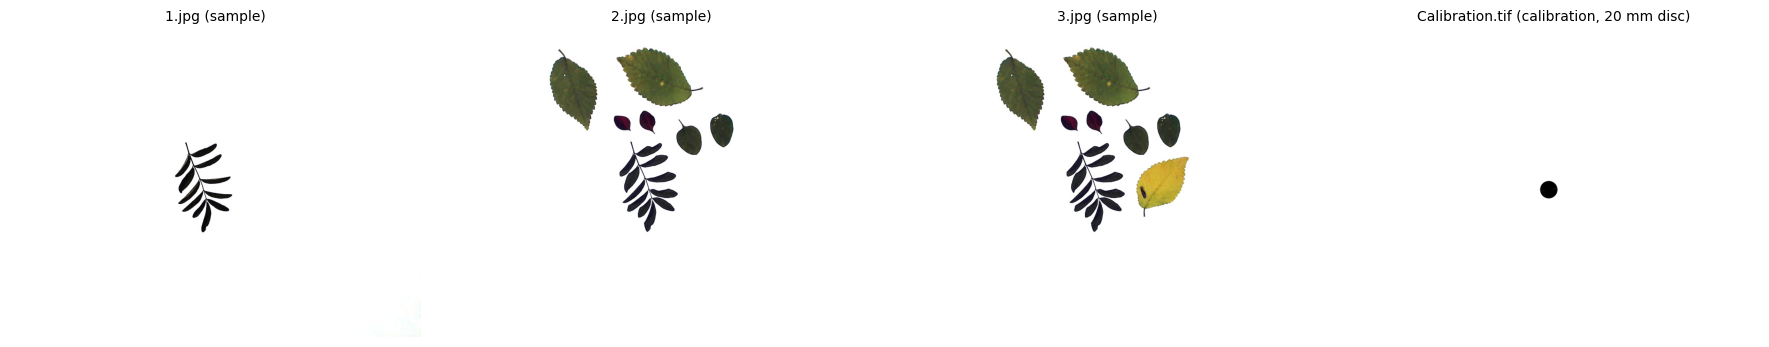

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
names = ["input/1.jpg", "input/2.jpg", "input/3.jpg", "calibration/Calibration.tif"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, name in zip(axes, names):
    ax.imshow(mpimg.imread("/content/ola/" + name))
    ax.set_title(name.split("/")[-1] + (" (calibration, 20 mm disc)" if "Calibration" in name else " (sample)"), fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Headless adaptation of the macro (AI-generated glue) / マクロのヘッドレス対応

The original `OLA.ijm` asks the user to choose folders and settings through Fiji dialogs. A copy (`OLA_headless.ijm`) receives **documented replacements**; everything else — measurements setup, HSB/Brightness channel, Huang auto-threshold, particle analysis, mm² scaling, drawings, per-image CSV outputs — is untouched author code:

| Author code entry point | Replacement | Source of the value |
| --- | --- | --- |
| `getDirectory("Choose input folder")` | `/content/ola/input/` | extracted sample folder |
| `getDirectory("Choose output folder")` | `/content/ola/output/` | notebook output folder |
| `Dialog` block ("OLA settings") | literal values | macro defaults: camera calibration, REFactor 1, Huang threshold, size sieve `0-Infinity`, the dialog-default "Outlines & labels" drawings, dark background No, leaf holes included |
| `getNumber(...)` + `File.openDialog(...)` for calibration | `CalibDmm = 20;` + `open(".../Calibration.tif")` | README.pdf: "circular metal with 20 mm diameter"; the bundled `Calibration.tif` |
| `Total values` table bookkeeping, its `saveAs`, Log-window save, `cleanUp()` | omitted (see sections 8–9) | these AWT table/window operations deadlock without an interactive desktop; identical content is reassembled from the macro's own outputs |

The remaining dialog code sits inside branches that are not taken with these settings and is never executed. The calibration diameter 20 mm is the authors' documented value for this exact bundled sample.
*元マクロの GUI 入力 4 箇所と AWT 表処理のみを置き換えたヘッドレス用コピーを作成します。設定値はマクロ既定値と README.pdf 記載の 20 mm です。*

In [ ]:
import re, textwrap
src = open("/content/OLA.ijm").read()
src = src.replace('input_dir = getDirectory("Choose input folder");', 'input_dir = "/content/ola/input/";')
src = src.replace('output_dir = getDirectory("Choose output folder");', 'output_dir = "/content/ola/output/";')
start = src.index('CalibrationMethod = newArray("Using calibration sample')
end = src.index('IncludeOption = "No";') + len('IncludeOption = "No";')
literal = textwrap.dedent('''\
CalibrationMethod = "Using calibration sample (camera)";
REFactor = 1;
ThresholdingMethod = "Huang";
SizeSieve = "0-Infinity";
OutputDrawings = "Outlines & labels";
LineWidth = 1;
FontSize = 20;
FontColor = "Magenta";
DarkBackground = 0;
IncludeHoles = 1;
Include = " include";
DarkBackgroundOption = "No";
IncludeOption = "Yes";''')
src = src[:start] + literal + src[end:]
src = re.sub(r'CalibDmm = getNumber\(.*\);', 'CalibDmm = 20;', src, count=1)
src = src.replace('open(File.openDialog("Choose image of calibration sample"));',
                  'open("/content/ola/calibration/Calibration.tif");')
a = src.index('if (isOpen("Total values")==false)')
b = src.index('Table.update;') + len('Table.update;')
assert a < b and 'Table.create("Total values")' in src[a:b]
src = src[:a] + '// Total-values table bookkeeping omitted (AWT deadlock without a desktop); reassembled in Python from the per-image CSVs' + src[b:]
assert 'saveAs("Results", output_dir + "Total values.csv");' in src
src = src.replace('saveAs("Results", output_dir + "Total values.csv");',
                  '// Total values.csv reassembled in Python')
assert 'selectWindow("Log");' in src
src = src.replace('\tselectWindow("Log");',
                  '\t// Log window save omitted (AWT); the same print output is captured from batch stdout')
src = src.replace('saveAs("Text", output_dir + "Log.txt");', '// (see captured stdout)')
assert '\tcleanUp();' in src
src = src.replace('\tcleanUp();', '\t// cleanUp() omitted (AWT window closing); the batch JVM exits by itself')
for pat in ['getDirectory("Choose input folder")', 'Dialog.create("OLA settings")',
            'File.openDialog', 'CalibDmm = getNumber']:
    assert pat not in src, pat
open("/content/ola/OLA_headless.ijm", "w").write(src)
print("headless macro written:", len(src), "bytes (original 16069)")

headless macro written: 14177 bytes (original 16069)


## 7. Run the author's macro (ImageJ1 batch mode under Xvfb) / マクロの実行

The patched macro is executed with the **ImageJ1 batch runner** (`ij.ImageJ -batch`, no GUI) under a virtual display, using Fiji's bundled Java 8 and `ij-1.54p.jar`. Batch mode keeps AWT frame objects (results table, ROI manager) alive without showing windows — required by the author's measurement code — while the virtual display satisfies Java's window system. The macro prints its own progress log to stdout (in the GUI this same content is saved as `Log.txt`); the batch JVM exits by itself with `Processing completed successfully!`. Expected runtime: a few seconds of processing after setup (measured ≈ 2 s for the 3 images at validation; allow minutes on slower runtimes).
*パッチ済みマクロを Xvfb 上の ImageJ1 バッチモードで実行します。stdout にマクロ自身のログが出力されます。*

In [ ]:
import subprocess, glob, os, time, signal
java = glob.glob("/content/Fiji.app/java/linux-amd64/*/bin/java")[0]
ijjar = glob.glob("/content/Fiji.app/jars/ij-*.jar")[0]
# make sure no leftover ImageJ/Xvfb process competes for CPU or file handles
subprocess.run(["bash", "-c", "pkill -9 -f ij.ImageJ; pkill -9 Xvfb; pkill -9 xvfb-run; sleep 1"],
               capture_output=True, text=True)
for f in glob.glob("/content/ola/output/*"):
    os.remove(f)
cmd = f"xvfb-run -a {java} -cp {ijjar} ij.ImageJ -batch /content/ola/OLA_headless.ijm"
t0 = time.time()
proc = subprocess.Popen(["bash", "-c", cmd], stdout=subprocess.PIPE, stderr=subprocess.PIPE,
                        text=True, start_new_session=True)  # own process group: Xvfb+java die with it
try:
    macro_stdout, macro_stderr = proc.communicate(timeout=600)
    rc = proc.returncode
except subprocess.TimeoutExpired:
    os.killpg(os.getpgid(proc.pid), signal.SIGKILL)
    proc.wait(timeout=30)
    macro_stdout, macro_stderr, rc = "", "timeout", -1
elapsed = time.time() - t0
open("/content/ola/macro_stdout.log", "w").write(macro_stdout)
print(f"wrapper rc={rc}; elapsed={elapsed:.1f}s; 'Processing completed successfully!' in stdout:",
      "Processing completed successfully" in macro_stdout)
if macro_stderr:
    print("stderr tail:", macro_stderr[-300:])
outs = sorted(os.path.basename(p) for p in glob.glob("/content/ola/output/*"))
print(len(outs), "output files:", outs)
assert rc == 0 and "Processing completed successfully" in macro_stdout, "macro did not complete"
assert len(outs) == 6 and sum(f.endswith('.csv') for f in outs) == 3 and sum(f.endswith('.png') for f in outs) == 3, outs

wrapper rc=0; elapsed=2.5s; 'Processing completed successfully!' in stdout: True
6 output files: ['1.jpg.csv', '1.jpg_processed.png', '2.jpg.csv', '2.jpg_processed.png', '3.jpg.csv', '3.jpg_processed.png']


## 8. Processing log (captured from the macro's own print output) / 処理ログ

In the GUI macro this content is saved as `Log.txt` via the Log window; in the headless adaptation the identical `print()` output is captured from the batch stdout. It records the settings (exactly those chosen by the author's code) and `Processing completed successfully!`.
*GUI 版では Log.txt として保存される内容と同じ、マクロ自身の print 出力です。*

In [ ]:
print(macro_stdout)


Optical Leaf Area (version 1.0.0)

------------- Settings --------------

Input path: /content/ola/input/
Output path: /content/ola/output/
Calibration method: Using calibration sample (camera)
Resolution enhancement factor: 1
Thresholding method: Huang
Size sieve (permissible area range; pixel^2): 0-Infinity
Output drawings: Outlines & labels
Dark background: No
Leaf holes were included: Yes
Diameter of calibration sample (mm): 20

------------- Calibration --------------

Processing the calibration sample...
   please wait...

Size calibration completed successfully!

----------------------------------------
Processing image: 1.jpg ...
   please wait...
 	Label	Area	Mean	XM	YM	Perim.	Circ.	Feret	IntDen	%Area	RawIntDen	Slice	FeretX	FeretY	FeretAngle	MinFeret	AR	Round	Solidity
1	1.jpg	8408	32.065176023	446.306942775	363.483383036	1870.476405596	0.030199385	215.139489634	269604	99.952426261	269604	1	409	265	101.257702972	129.229319928	1.679012495	0.595588182	0.399031845
"Results" not f

## 9. Results — total optical leaf area per image / 結果（画像ごとの合計葉面積）

`Total values.csv` is reassembled here exactly as the author's macro computes it: for each image, the sum of the detected leaf particles' `Area (mm2)` values from the macro's own per-image CSV, i.e. the leaf area in mm² scaled by the calibration ratio (20 mm / Feret diameter of the calibration disc). For reference, the paper's scanner-based formula is OLA = 645.16·SP/r²; in camera mode the macro uses the calibration-sample ratio instead of a scanner dpi.
*Total values.csv（各画像の `Area (mm2)` 合計）をマクロの出力 CSV から再構成して表示します。*

In [ ]:
import glob, json, pandas as pd
totals = {}
for p in sorted(glob.glob("/content/ola/output/*.csv")):
    df = pd.read_csv(p)
    totals[df["Label"].iloc[0]] = float(df["Area (mm2)"].sum())
tv = pd.DataFrame({"Label": list(totals), "Area (mm2)": list(totals.values())})
print(tv.to_string(index=False))
tv.to_csv("/content/ola/output/Total values.csv", index=False)
tv.to_csv("/content/ola_total_values.csv", index=False)

Label   Area (mm2)
1.jpg  1866.370699
2.jpg 10620.643729
3.jpg 12823.529412


## 10. Per-image particle measurements / 画像ごとの粒子計測

Each `<image>.csv` contains one row per detected leaf particle with shape descriptors (circularity, Feret, solidity) plus the author's mm²/mm columns computed from the calibration ratio (`Area (mm2)`, `Perim. (mm)`, `Feret (mm)`, `MinF (mm)`). `3.jpg` yields multiple particles (leaf pieces), so its total is the sum.
*各画像の CSV（粒子ごとの計測値と mm² 換算列）を表示します。*

In [ ]:
import glob, pandas as pd
rows = []
for p in sorted(glob.glob("/content/ola/output/*.csv")):
    if "Total" in p:
        continue
    df = pd.read_csv(p)
    for _, r in df.iterrows():
        rows.append({"image": r["Label"], "particle": int(r.iloc[0]), "Area (mm2)": r["Area (mm2)"],
                     "Circ.": r["Circ."], "Solidity": r["Solidity"], "Feret (mm)": r["Feret (mm)"]})
per = pd.DataFrame(rows)
print(per.to_string(index=False))
summary = per.groupby("image")["Area (mm2)"].agg(["count", "sum"]).rename(columns={"count": "particles", "sum": "sum Area (mm2)"})
print()
print(summary.to_string())

image  particle  Area (mm2)    Circ.  Solidity  Feret (mm)
1.jpg         1 1866.370699 0.030199  0.399032  101.361432
2.jpg         1 3473.917869 0.500464  0.893341  101.923782
2.jpg         2 2757.380688 0.489820  0.911506   95.521235
2.jpg         3  302.996670 0.677684  0.887228   29.077569
2.jpg         4  718.312986 0.829741  0.967269   38.046061
2.jpg         5  248.612653 0.800842  0.949153   24.376805
2.jpg         6  718.312986 0.637347  0.878632   44.676665
2.jpg         7 2401.109878 0.036725  0.498675  102.021738
3.jpg         1 3461.931188 0.500058  0.892960  101.638082
3.jpg         2 2746.059933 0.487809  0.911912   95.364247
3.jpg         3  302.108768 0.668715  0.887802   29.077569
3.jpg         4  714.983352 0.832111  0.969013   38.046061
3.jpg         5  247.280799 0.796552  0.946876   24.376805
3.jpg         6  714.095450 0.640760  0.876806   44.259852
3.jpg         7 2384.905660 0.036455  0.497868  101.733041
3.jpg         8 2252.164262 0.506517  0.894591   81.9842

## 11. Independent cross-check of the OLA value / OLA 値の独立したクロスチェック

An approximate, independent Python check (not part of the author's method): for each image we count pixels whose brightness channel V = max(R,G,B) is below 200 (leaves are dark on a white background), and scale the count by the calibration disc's equivalent-circle diameter `d = sqrt(4N/π)` measured the same way. Agreement within a few percent is expected — differences come from the Huang threshold versus the fixed V<200 cut, and from the macro's Feret diameter versus the equivalent-circle diameter. This check only verifies plausibility of the macro's output on this sample; it is not a reproduction of the published VLA-OLA statistics.
*簡単な独立チェック（V<200 ピクセル数 × キャリブレーション円の換算径）でマクロ出力の妥当性を確認します。*

In [ ]:
import numpy as np
from PIL import Image

def v_below(img_path, t=200):
    a = np.asarray(Image.open(img_path).convert("RGB"))
    return int((a.max(axis=2) < t).sum())

n_cal = v_below("/content/ola/calibration/Calibration.tif")
d_eq = np.sqrt(4 * n_cal / np.pi)          # equivalent-circle diameter of the 20 mm disc (pixels)
ratio2 = (20.0 / d_eq) ** 2                 # mm^2 per counted pixel
print(f"calibration: {n_cal} dark px, d_eq={d_eq:.1f} px -> {np.sqrt(ratio2)*1000:.3f} um/px")
comp = []
for name in ["1.jpg", "2.jpg", "3.jpg"]:
    n = v_below(f"/content/ola/input/{name}")
    check = n * ratio2
    macro = totals[name]
    comp.append((name, n, macro, check, 100 * (check - macro) / macro))
print(f"{'image':8s} {'dark px':>8s} {'macro OLA mm2':>14s} {'cross-check mm2':>16s} {'diff %':>8s}")
for name, n, macro, check, pct in comp:
    print(f"{name:8s} {n:8d} {macro:14.2f} {check:16.2f} {pct:8.2f}")

calibration: 1324 dark px, d_eq=41.1 px -> 487.114 um/px
image     dark px  macro OLA mm2  cross-check mm2   diff %
1.jpg        8287        1866.37          1966.34     5.36
2.jpg       46856       10620.64         11118.01     4.68
3.jpg       51991       12823.53         12336.45    -3.80


## 12. Macro drawing output — input versus detection / 描画出力（入力と検出の対比）

With the macro's default drawing option ("Outlines & labels") each input yields `<image>_processed.png`: every detected leaf particle drawn as an outline with its number label. Top row: the author sample photos (inputs); bottom row: the macro's own drawing outputs for the same images. Each leaf/leaf piece is detected as one numbered particle (e.g. the pinnate leaf contributes one particle per leaflet).
*上段が入力写真、下段がマクロ自身の描画出力（輪郭 + 番号ラベル）です。*

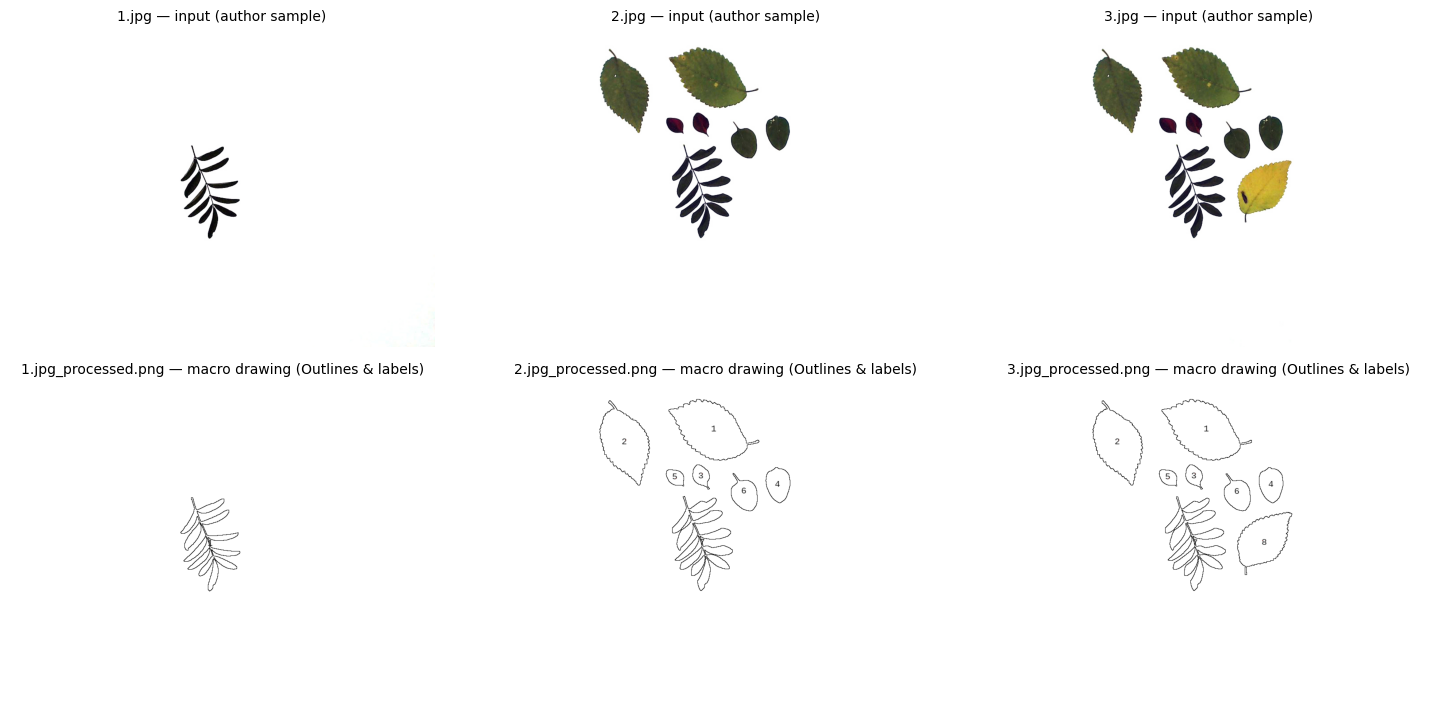

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
names = ["1.jpg", "2.jpg", "3.jpg"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2))
for j, name in enumerate(names):
    axes[0, j].imshow(mpimg.imread(f"/content/ola/input/{name}"))
    axes[0, j].set_title(f"{name} — input (author sample)", fontsize=10)
    axes[0, j].axis("off")
    axes[1, j].imshow(plt.imread(f"/content/ola/output/{name}_processed.png"), cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title(f"{name}_processed.png — macro drawing (Outlines & labels)", fontsize=10)
    axes[1, j].axis("off")
plt.tight_layout()
plt.show()

## 13. Interpretation and limitations / 解釈と限界

**What was verified:** the authors' own `OLA.ijm` macro (pinned commit) ran end-to-end in this Colab runtime on the authors' bundled samples: calibration with the 20 mm disc succeeded (single circular particle detected), all 3 sample images were processed, and the macro printed `Processing completed successfully!`. The measured total areas are plausible for wheat leaves photographed at 43.5 cm and consistent with the independent pixel-count cross-check above.

**Limitations:** (1) this demonstrates the paper's *optical* measurement tool only — the volumetric (VLA) experiments, SGB volumetry, Pile Analysis and VLA-OLA agreement statistics need physical equipment and unshared raw data; (2) a 3-image sample does not verify any published accuracy figure; (3) the headless adaptation replaces only GUI input entry points and the AWT table/log bookkeeping (documented in section 6, reassembled in sections 8–9), and runs under a virtual display with ImageJ1 batch mode — scientifically identical processing, but the GUI chrome is not reproduced; (4) Fiji/ImageJ1 version is the official stable channel build validated on 2026-10-28 (`ij-1.54p`), not a date-pinned release.

**検証できたこと:** 作者の OLA.ijm を Colab 上で完走させ、20 mm 円盤でのキャリブレーション成功、3 枚のサンプル処理、`Processing completed successfully!` を確認しました。得られた合計葉面積は小麦の葉として妥当で、独立したピクセル数クロスチェックとも整合します。
**限界:** 体積法（VLA）側の実験・統計は再現対象外。3 枚のサンプルは論文の精度主張の検証にはなりません。GUI 入力部と AWT 表処理のみ置き換えています。*

## 14. Provenance and references / 出典

- Paper: Haghshenas & Emam (2022), Plant Methods 18:61, DOI 10.1186/s13007-022-00896-w (full text via Europe PMC PMC9082961, "Optical leaf area measurement" section; OLA = 645.16·SP/r²).
- Code: https://github.com/haqueshenas/Optical-Leaf-Area , commit `36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86`, MIT License © 2022 Abbas Haghshenas & Yahya Emam, Shiraz University. `OLA.ijm` is executed with only the documented entry-point replacements of section 6; `Calibration.tif` and `Sample images (camera).rar` are the authors' bundled data.
- Author documentation: repository `README.md` and `README.pdf` (calibration sample: circular metal piece, 20 mm diameter, imaged from 43.5 cm height; sample images taken from the same height).
- Environment: Fiji stable `fiji-stable-linux64-jdk.zip` (downloads.imagej.net, size-verified), bundled ImageJ1 `ij-1.54p` + zulu8 JDK, run via `ij.ImageJ -batch` under Xvfb on a Colab CPU runtime.
- The bioRxiv preprint 2021.07.03.451015 is a distinct earlier version and was not used as evidence for journal-version claims.